[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ErvinasE/commit-message-generator/blob/main/1.5/cnn_One_Image_OpenImages.ipynb)

# Vaizdų klasifikavimas, objektų aptikimas ir segmentavimas

>>>>***Su viena nuotrauka***

Šis sąsiuvinis yra perdarytas dėstytojo A. Laukaičio sąsiuvinis `cnn_One_Image.ipynb`. Čia nieko nemokome:
naudojame jau išmokytus tinklus ir žiūrime, ką jie „mato“ verslo aplinkos nuotraukose.

| | Originalas | Šis sąsiuvinis |
|---|---|---|
| Nuotraukos | Wikimedia: Vilnius, Paryžius, Klaipėda ir kt. | 6 nuotraukos iš [Open Images](https://storage.googleapis.com/openimages/web/index.html) duomenų rinkinio: kavinė, biuras, parduotuvė, vaisių prekystalis, gatvė (aplankas `data/images/`) |
| 1 skyrius: klasifikavimas | 2 TF Hub EfficientNetV2-S modeliai (ImageNet-21k ir ImageNet-1k) | 2 `keras.applications` modeliai: didelis EfficientNetV2-S ir mažas MobileNetV3-Large (abu ImageNet-1k) |
| 2 skyrius: objektų aptikimas | SSD MobileNet V2, Open Images V4 (600 klasių), iš TF Hub | **tas pats** SSD MobileNet V2 Open Images V4 modelis, iš TensorFlow modelių saugyklos |
| 3 skyrius: segmentavimas | HRNet, ADE20K (150 klasių), iš TF Hub | DeepLabV3 MobileNetV2, **tas pats** ADE20K (150 klasių), iš TensorFlow modelių saugyklos |

Modeliai parsisiunčiami tiesiai iš „Google“ TensorFlow modelių saugyklos (`storage.googleapis.com/download.tensorflow.org`),
o ne per TF Hub (jis dabar nukreipia į Kaggle). Todėl nereikia `tensorflow_hub` paketo.

Open Images yra „Google“ duomenų rinkinys su ~9 mln. „Flickr“ nuotraukų; visos jos turi CC BY 2.0 licenciją.
Nuotraukų autoriai ir nuorodos yra faile `data/images.csv`. Norėdami naudoti savo nuotraukas, įdėkite jas į
`data/images/` ir pridėkite eilutę į `data/images.csv`.

---
# 1 skyrius. Vaizdų klasifikavimas

>>>>***Su 2 modeliais***

In [1]:
#@title Bibliotekos

import os
import io
import tarfile

import numpy as np
import pandas as pd
import requests
import tensorflow as tf
import keras
import matplotlib.pyplot as plt
from PIL import Image, ImageColor, ImageDraw, ImageFont
from IPython.display import HTML, display

%config InlineBackend.figure_format = 'jpeg'   # nuotraukas rodome JPEG formatu, kad sąsiuvinis būtų mažesnis

### Nuotraukos

Lentelėje `images.csv` yra kiekvienos nuotraukos failas, pavadinimas, Open Images ID, autorius ir licencija.
Colab'e failai parsisiunčiami iš GitHub, lokaliai imami iš aplanko `data/`.

In [2]:
GITHUB_BRANCH = 'main'
DATA_URL = f'https://raw.githubusercontent.com/ErvinasE/commit-message-generator/{GITHUB_BRANCH}/1.5/data/'
DATA_DIR = 'data/' if os.path.exists('data/images.csv') else DATA_URL


def read_bytes(path):
    """Grąžina failo turinį: iš interneto (Colab) arba iš disko (lokaliai)."""
    if path.startswith('http'):
        response = requests.get(path, timeout=60)
        response.raise_for_status()
        return response.content
    with open(path, 'rb') as f:
        return f.read()


photos = pd.read_csv(io.BytesIO(read_bytes(DATA_DIR + 'images.csv')))
photos['key'] = photos['file'].str.replace('images/', '').str.replace('.jpg', '')
photos[['key', 'name', 'author', 'license']]

,key,name,author,license
0,kavine_lauke,Kavinė iš lauko,Shinya Suzuki,https://creativecommons.org/licenses/by/2.0/
1,biuras,Biuras,Ged Carroll,https://creativecommons.org/licenses/by/2.0/
2,parduotuve,Parduotuvė (prekybos salė),Jaro Larnos,https://creativecommons.org/licenses/by/2.0/
3,vaisiu_prekystalis,Vaisių prekystalis,e_chaya,https://creativecommons.org/licenses/by/2.0/
4,gatve,Gatvė su transportu,Nina,https://creativecommons.org/licenses/by/2.0/
5,kavine_viduje,Kavinė viduje,Market Lane Coffee,https://creativecommons.org/licenses/by/2.0/


In [3]:
#@title Pagalbinės funkcijos nuotraukoms įkelti, parodyti ir klasifikuoti

def load_photo(key):
    """Grąžina nuotrauką kaip uint8 masyvą (aukštis, plotis, 3)."""
    file = photos.set_index('key').loc[key, 'file']
    image = Image.open(io.BytesIO(read_bytes(DATA_DIR + file))).convert('RGB')
    return np.array(image)


def show_image(image, title='', size=8):
    plt.figure(figsize=(size, size))
    plt.imshow(image)
    plt.axis('off')
    plt.title(title)
    plt.show()


def top_classes(image, classifier, input_size, top=4):
    """Klasifikuoja nuotrauką ir grąžina labiausiai tikėtinas klases: [(klasė, tikimybė), ...]."""
    x = tf.image.resize_with_pad(image[None].astype('float32'), input_size, input_size)  # kvadratas su juostomis
    probabilities = classifier(x).numpy()          # modelio išėjimas jau yra tikimybės (softmax)
    decoded = keras.applications.imagenet_utils.decode_predictions(probabilities, top=top)[0]
    return [(class_name, float(p)) for wordnet_id, class_name, p in decoded]


def run_model_on_image(image, classifier, input_size):
    """4 labiausiai tikėtinos klasės kaip tekstas."""
    line = ''
    for i, (class_name, p) in enumerate(top_classes(image, classifier, input_size)):
        line += f'{i + 1:2}) {class_name};   p = {p:.4f}' + '\n'
    return line


def answers_html(answer1, answer2):
    return HTML("<h1 style='font-size: 22px; color: blue;'>Modelio 1 (EfficientNetV2-S) atsakymas <br><br><i>"
                + answer1.replace('\n', '<br>') + "</i></h1><br>"
                + "<h1 style='font-size: 22px; color: green;'>Modelio 2 (MobileNetV3-Large) atsakymas <br><br><i>"
                + answer2.replace('\n', '<br>') + "</i></h1>")

### Įkeliame 2 klasifikavimo modelius

Abu modeliai išmokyti su **ImageNet** (1,3 mln. nuotraukų, 1 000 klasių: gyvūnai, transportas, daiktai, vietos).
`weights='imagenet'` parsisiunčia išmokytus svorius. Abiejų modelių paskutinis sluoksnis yra *softmax*,
todėl jie iš karto grąžina tikimybes (originale `tf.nn.softmax` reikėjo taikyti patiems).
Abu modeliai patys normalizuoja taškų reikšmes, todėl jiems paduodame reikšmes 0–255.

* **Modelis 1: EfficientNetV2-S**: didelis ir tikslus (~21 mln. parametrų), nuotrauka 384×384;
* **Modelis 2: MobileNetV3-Large**: mažas ir greitas (~5 mln. parametrų), skirtas telefonams, nuotrauka 224×224.

In [4]:
#@title Įkeliame 2 modelius

input_size = 384
classifier = keras.applications.EfficientNetV2S(weights='imagenet')

input_size2 = 224
classifier2 = keras.applications.MobileNetV3Large(weights='imagenet', input_shape=(input_size2, input_size2, 3))

print('Modelis 1: {:,} parametrų'.format(classifier.count_params()))
print('Modelis 2: {:,} parametrų'.format(classifier2.count_params()))

Modelis 1: 21,612,360 parametrų
Modelis 2: 5,507,432 parametrų


---
## Du modeliai ir viena nuotrauka

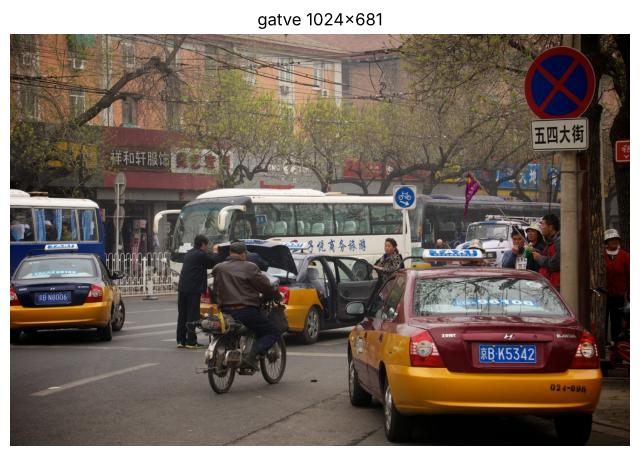

In [5]:
#@title Pasirinkite nuotrauką { run: "auto" }

image_name = 'gatve'  # @param ['kavine_lauke', 'biuras', 'parduotuve', 'vaisiu_prekystalis', 'gatve', 'kavine_viduje']

original_image = load_photo(image_name)
show_image(original_image, f'{image_name} {original_image.shape[1]}×{original_image.shape[0]}')

model_answer = run_model_on_image(original_image, classifier, input_size)
model_answer2 = run_model_on_image(original_image, classifier2, input_size2)

answers_html(model_answer, model_answer2)

### Visos 6 nuotraukos

Originale vienu metu buvo žiūrima tik viena nuotrauka. Čia dar peržiūrime visas 6 nuotraukas iš karto:
kiekvieno modelio labiausiai tikėtina klasė ir jos tikimybė.

In [6]:
rows = []
for key in photos['key']:
    img = load_photo(key)
    name1, p1 = top_classes(img, classifier, input_size, top=1)[0]
    name2, p2 = top_classes(img, classifier2, input_size2, top=1)[0]
    rows.append({'nuotrauka': key, 'Modelis 1 (EfficientNetV2-S)': f'{name1} ({p1:.0%})',
                 'Modelis 2 (MobileNetV3-Large)': f'{name2} ({p2:.0%})'})
pd.DataFrame(rows)

,nuotrauka,Modelis 1 (EfficientNetV2-S),Modelis 2 (MobileNetV3-Large)
0,kavine_lauke,restaurant (71%),restaurant (45%)
1,biuras,desk (87%),sewing_machine (27%)
2,parduotuve,shopping_basket (88%),shopping_basket (33%)
3,vaisiu_prekystalis,grocery_store (68%),grocery_store (57%)
4,gatve,cab (76%),cab (80%)
5,kavine_viduje,restaurant (77%),restaurant (72%)


**Ką matome:**
* ImageNet neturi klasių „kavinė“ ar „biuras“, todėl modeliai renkasi artimiausią turimą klasę: kavinės tampa
  `restaurant`, biuras `desk` (stalas), vaisių prekystalis `grocery_store` (bakalėjos parduotuvė).
* Klasifikatorius visai nuotraukai duoda **vieną** atsakymą, todėl dažnai laimi didžiausias arba ryškiausias objektas:
  gatvės nuotrauka yra `cab` (taksi priekiniame plane), parduotuvės nuotrauka `shopping_basket` (vaiko rankose esantis krepšelis).
* Didelis modelis (EfficientNetV2-S) visose 6 nuotraukose atsakė prasmingai ir užtikrinčiau (68–88 %).
  Mažas modelis (MobileNetV3) biurą palaikė `sewing_machine` (siuvimo mašina, 27 %), o jo tikimybės dažniausiai mažesnės.
  Tai įprasta kaina už ~4 kartus mažesnį ir greitesnį modelį.

---

## Iškerpame nuotraukos gabalą ir bandome dar kartą

Modeliai visada atsako apie **visą** nuotrauką. Jei iškirpsime gabalą, pamatysime, ką jie atpažįsta jame.
`x` ir `y` yra viršutinio kairiojo kampo padėtis procentais, `cut_size_in_pixels` yra iškarpos dydis taškais.
Numatytoji iškarpa (`x=28, y=48`, 300 taškų) gatvės nuotraukoje yra motoroleris su vairuotoju.

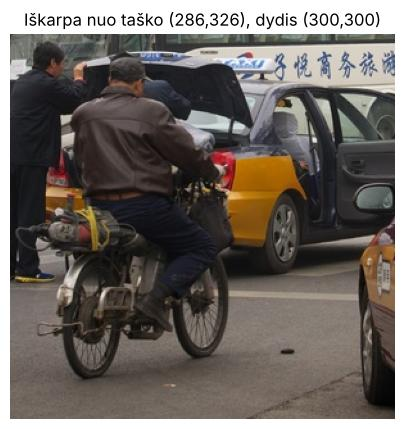

In [7]:
#@title Įveskite iškarpos viršutinio kairiojo kampo koordinates (%) { run: "auto" }

x = 28 # @param {type:"slider", min:0, max:100, step:1}
y = 48 # @param {type:"slider", min:0, max:100, step:1}

cut_size_in_pixels = 300 # @param {type:"integer"}

x_cord = int(original_image.shape[1] * x / 100)
y_cord = int(original_image.shape[0] * y / 100)

image_cut = original_image[y_cord:y_cord + cut_size_in_pixels, x_cord:x_cord + cut_size_in_pixels, :]

show_image(image_cut, f'Iškarpa nuo taško ({x_cord},{y_cord}), dydis ({image_cut.shape[1]},{image_cut.shape[0]})', size=5)

model_answer = run_model_on_image(image_cut, classifier, input_size)
model_answer2 = run_model_on_image(image_cut, classifier2, input_size2)

answers_html(model_answer, model_answer2)

---
# 2 skyrius. Objektų aptikimas (*object detection*)

Klasifikatorius pasako, **kas** yra nuotraukoje. Detektorius pasako, kas ir **kur**: kiekvienam radiniui grąžina
stačiakampį (*bounding box*), klasę ir tikimybę.

**SSD MobileNet V2** (*Single Shot Detector*) yra greitas detektorius, išmokytas su Open Images V4 (600 objektų klasių).
Tai tas pats modelis kaip originale, tik parsisiunčiamas kaip TensorFlow `SavedModel` archyvas.
Jis grąžina:
* `detection_boxes`: stačiakampiai `[ymin, xmin, ymax, xmax]`, koordinatės nuo 0 iki 1;
* `detection_classes`: klasių numeriai (1–600). Pavadinimus imame iš `data/oid_v4_labels.csv`;
* `detection_scores`: tikimybės.

In [8]:
#@title Įkeliame detektorių ir jo klasių pavadinimus

MODELS_URL = 'https://storage.googleapis.com/download.tensorflow.org/models/'


def download_and_extract(file_name, url):
    """Parsisiunčia .tar.gz archyvą (vieną kartą) ir jį išskleidžia. Grąžina aplanką."""
    archive = keras.utils.get_file(file_name, url)
    folder = os.path.join(os.path.dirname(archive), file_name.replace('.tar.gz', ''))
    if not os.path.exists(folder):
        with tarfile.open(archive) as tar:
            tar.extractall(os.path.dirname(archive), filter='data')
    return folder


detector_dir = download_and_extract('ssd_mobilenet_v2_oid_v4_2018_12_12.tar.gz',
                                    MODELS_URL + 'object_detection/ssd_mobilenet_v2_oid_v4_2018_12_12.tar.gz')
detector = tf.saved_model.load(os.path.join(detector_dir, 'saved_model')).signatures['serving_default']

detector_labels = pd.read_csv(io.BytesIO(read_bytes(DATA_DIR + 'oid_v4_labels.csv'))).set_index('id')['name']
print('Klasių:', len(detector_labels), ' pvz.:', ', '.join(detector_labels.sample(8, random_state=1)))

INFO:tensorflow:Saver not created because there are no variables in the graph to restore


Klasių: 601  pvz.: Book, Handbag, Shellfish, Flower, Fax, Traffic light, Pizza cutter, Facial tissue holder


In [9]:
#@title Pagalbinės funkcijos stačiakampiams piešti

def get_font(size=20):
    try:
        import matplotlib.font_manager as fm
        return ImageFont.truetype(fm.findfont('DejaVu Sans'), size)
    except Exception:
        return ImageFont.load_default()


def draw_bounding_box_on_image(image, ymin, xmin, ymax, xmax, color, font, thickness=4, display_str=''):
    """Nupiešia vieną stačiakampį su užrašu (PIL paveikslėlyje)."""
    draw = ImageDraw.Draw(image)
    im_width, im_height = image.size
    left, right, top, bottom = xmin * im_width, xmax * im_width, ymin * im_height, ymax * im_height
    draw.line([(left, top), (left, bottom), (right, bottom), (right, top), (left, top)], width=thickness, fill=color)

    text_left, text_top, text_right, text_bottom = font.getbbox(display_str)
    text_width, text_height = text_right - text_left, text_bottom - text_top
    margin = int(np.ceil(0.1 * text_height))
    # Užrašas virš stačiakampio, o jei netelpa (stačiakampis prie viršaus) - po viršutiniu kraštu
    label_top = top - text_height - 2 * margin if top > text_height + 2 * margin else top
    draw.rectangle([(left, label_top), (left + text_width + 2 * margin, label_top + text_height + 2 * margin)], fill=color)
    draw.text((left + margin, label_top + margin - text_top), display_str, fill='black', font=font)


def draw_boxes(image, boxes, class_names, scores, max_boxes=20, min_score=0.1):
    """Uždeda stačiakampius su klase ir tikimybe ant nuotraukos (uint8 masyvo)."""
    colors = list(ImageColor.colormap.values())
    font = get_font(max(14, image.shape[1] // 50))
    image_pil = Image.fromarray(image)
    for i in range(min(boxes.shape[0], max_boxes)):
        if scores[i] >= min_score:
            ymin, xmin, ymax, xmax = boxes[i]
            display_str = '{}: {}%'.format(class_names[i], int(100 * scores[i]))
            color = colors[sum(map(ord, class_names[i])) % len(colors)]
            draw_bounding_box_on_image(image_pil, ymin, xmin, ymax, xmax, color, font, display_str=display_str)
    return np.array(image_pil)


def run_detector(detector, image, min_score=0.1, show=True):
    result = detector(tf.constant(image[None]))          # detektorius tikisi uint8 paveikslėlio [1, aukštis, plotis, 3]
    result = {key: value[0].numpy() for key, value in result.items()}
    result['detection_class_names'] = [detector_labels[int(c)] for c in result['detection_classes']]

    found = result['detection_scores'] >= min_score
    print('Rasta %d objektų (tikimybė ≥ %.0f %%).' % (found.sum(), 100 * min_score))
    for name, score in zip(np.array(result['detection_class_names'])[found], result['detection_scores'][found]):
        print(f'   {name:20} {score:.2f}')

    image_with_boxes = draw_boxes(image.copy(), result['detection_boxes'], result['detection_class_names'],
                                  result['detection_scores'], min_score=min_score)
    if show:
        show_image(image_with_boxes, size=12)
    return result, image_with_boxes

>## Detektorius

Pirmiausia visa pasirinkta nuotrauka. Pirmas paleidimas trunka ilgiau, nes TensorFlow paruošia skaičiavimų grafą.

Rasta 6 objektų (tikimybė ≥ 10 %).
   Car                  0.59
   Car                  0.56
   Taxi                 0.52
   Bicycle              0.39
   Person               0.37
   Wheel                0.34


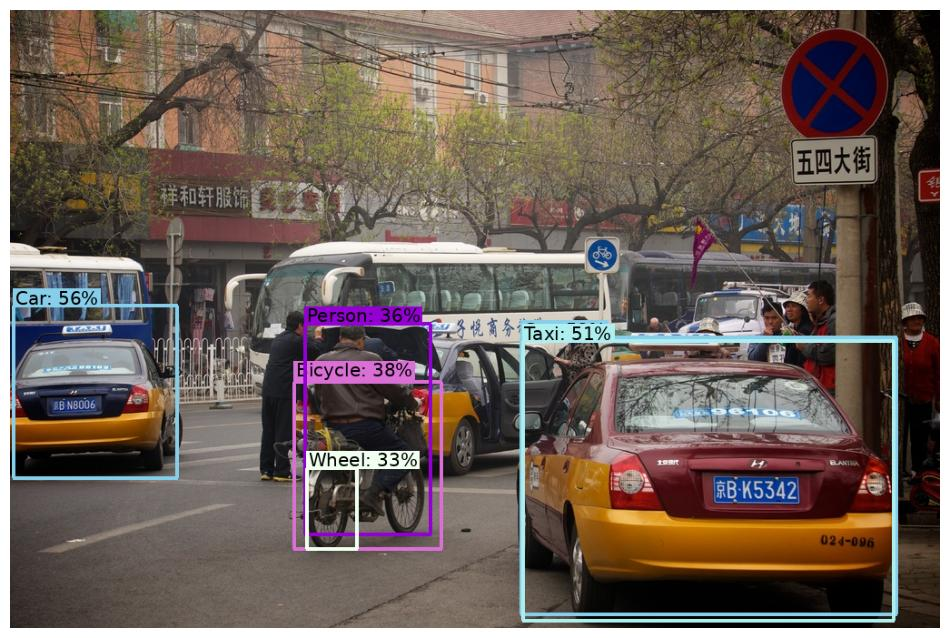

In [10]:
detector_output, _ = run_detector(detector, original_image)

Dabar tik iškarpa iš 1 skyriaus.

Rasta 7 objektų (tikimybė ≥ 10 %).
   Bicycle              0.76
   Wheel                0.54
   Man                  0.48
   Car                  0.40
   Wheel                0.38
   Man                  0.33
   Clothing             0.32


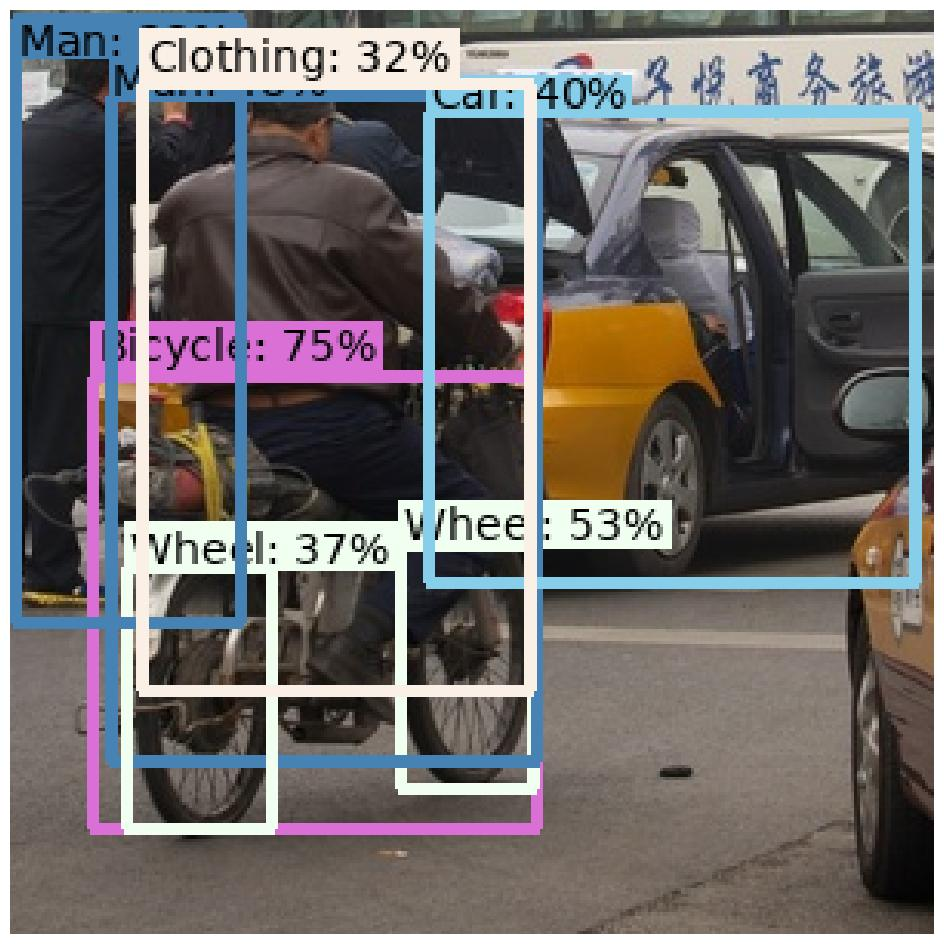

In [11]:
detector_output_cut, _ = run_detector(detector, np.ascontiguousarray(image_cut))

### Detektorius visose 6 nuotraukose

kavine_lauke


Rasta 1 objektų (tikimybė ≥ 10 %).
   Building             0.49
biuras


Rasta 4 objektų (tikimybė ≥ 10 %).
   Office building      0.80
   Person               0.60
   Desk                 0.48
   Human face           0.34
parduotuve


Rasta 4 objektų (tikimybė ≥ 10 %).
   Convenience store    0.78
   Person               0.53
   Clothing             0.51
   Jacket               0.31
vaisiu_prekystalis


Rasta 0 objektų (tikimybė ≥ 10 %).
gatve


Rasta 6 objektų (tikimybė ≥ 10 %).
   Car                  0.59
   Car                  0.56
   Taxi                 0.52
   Bicycle              0.39
   Person               0.37
   Wheel                0.34
kavine_viduje


Rasta 2 objektų (tikimybė ≥ 10 %).
   Person               0.36
   Building             0.32


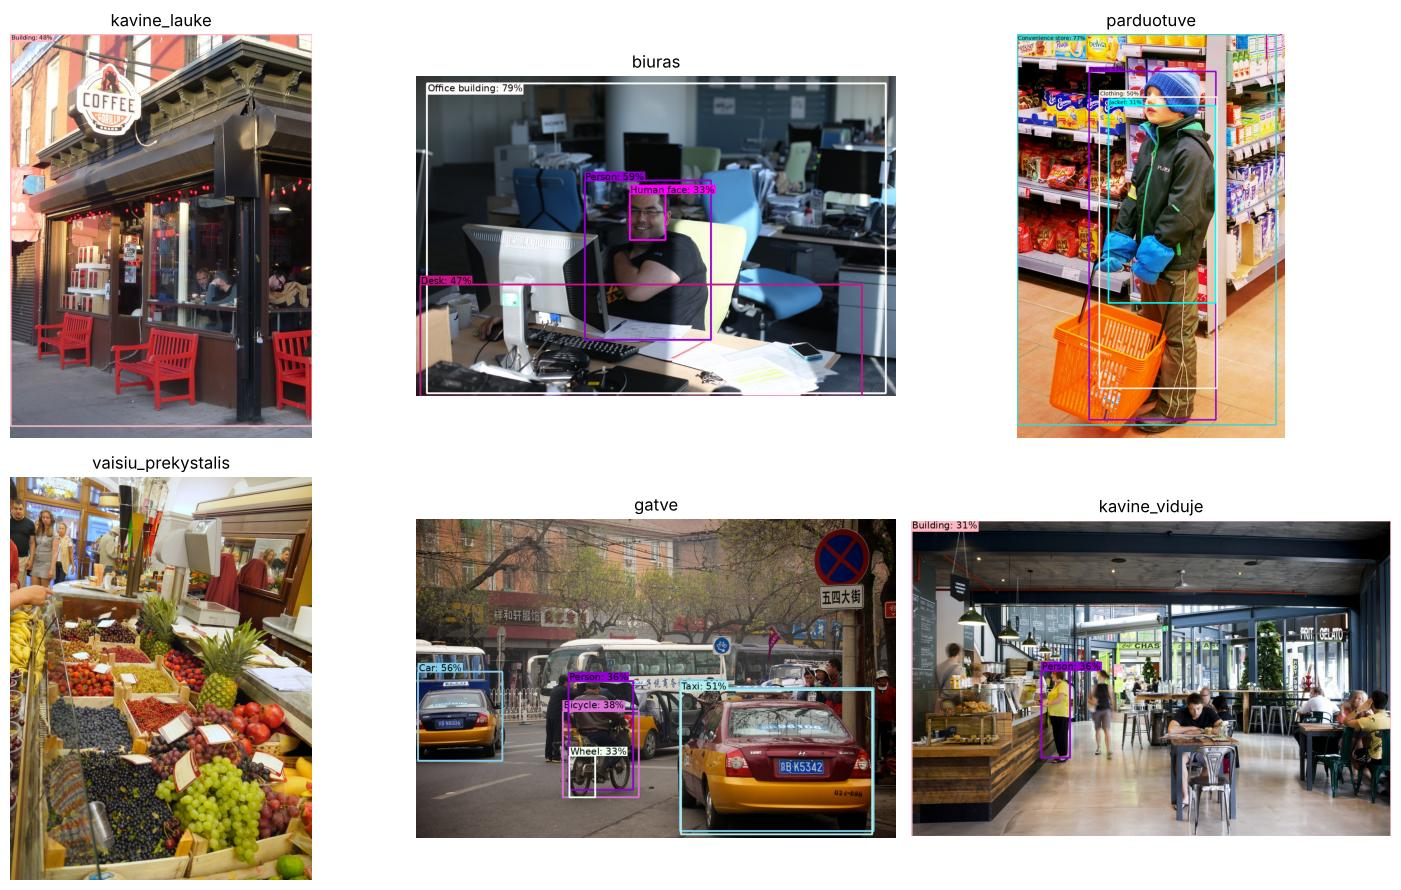

In [12]:
plt.figure(figsize=(15, 9))
for i, key in enumerate(photos['key']):
    print(key)
    _, boxed = run_detector(detector, load_photo(key), show=False)
    plt.subplot(2, 3, i + 1)
    plt.imshow(boxed)
    plt.axis('off')
    plt.title(key)
plt.tight_layout()
plt.show()

**Ką matome:**
* Gatvės nuotraukoje detektorius rado automobilius, taksi, dviratį, žmogų ir ratą, tačiau **nerado** autobusų ir daugumos pėsčiųjų.
* Iškarpoje tas pats dviratis rastas su didesne tikimybe (76 % vietoje 39 %): SSD MobileNet viduje nuotrauką sumažina
  iki 300×300 taškų, todėl dideliame kadre maži objektai tampa vos keliais taškais.
* Vaisių prekystalio nuotraukoje nerasta **nieko** (nė vieno objekto su tikimybe ≥ 10 %), nors Open Images turi klases
  `Pineapple`, `Grape`, `Fruit`. Greitas „mobilus“ detektorius tankiose scenose su daug smulkių objektų veikia prastai.
  Originale komentare minimas tikslesnis (bet ~5 kartus didesnis ir lėtesnis) Faster R-CNN Inception-ResNet V2 modelis;
  jis yra toje pačioje saugykloje: `object_detection/faster_rcnn_inception_resnet_v2_atrous_oid_v4_2018_12_12.tar.gz`.
* Šio modelio konfigūracijoje (`pipeline.config`) nustatyta `score_threshold: 0.3`, t. y. modelis pats atmeta radinius,
  kurių tikimybė mažesnė nei 30 %. Todėl mūsų slenkstis 10 % (`min_score=0.1`, kaip originale) praktiškai nieko nekeičia.
  Originalo TF Hub versija grąžindavo visus 100 radinių (ir labai mažų tikimybių), todėl ten buvo rašoma „Found 100 objects“.
* Open Images turi ir „scenos“ klasių (`Office building`, `Convenience store`, `Building`), todėl kai kurie stačiakampiai
  apima visą nuotrauką.

---
# 3 skyrius. Vaizdo segmentavimas (*semantic segmentation*)

Segmentavimo modelis klasę priskiria **kiekvienam nuotraukos taškui**: šis taškas yra kelias, šis pastatas, šis žmogus.

**DeepLabV3 (MobileNetV2)** išmokytas su ADE20K duomenų rinkiniu (150 klasių: siena, pastatas, dangus, grindys,
medis, kelias, žmogus, automobilis ir t. t.). Tai tas pats klasių rinkinys kaip originalo HRNet modelio.
Klasių pavadinimai yra faile `data/ade20k_labels.csv` (0 = „kita“, 1–150 = ADE20K klasės).

Šis modelis išsaugotas senu TensorFlow 1 „užšaldyto grafo“ (*frozen graph*) formatu, todėl įkeliame jį su
`tf.compat.v1.wrap_function` ir pasirenkame įėjimą (`ImageTensor`) bei du išėjimus:
* `SemanticPredictions`: kiekvieno taško klasės numeris;
* `ResizeBilinear_2`: kiekvieno taško 151 klasės įverčiai (*logitai*). Iš jų su *softmax* gauname 151 tikimybių žemėlapį,
  kaip originale.

In [13]:
#@title Įkeliame segmentavimo modelį ir klasių pavadinimus

seg_dir = download_and_extract('deeplabv3_mnv2_ade20k_train_2018_12_03.tar.gz',
                               MODELS_URL + 'deeplabv3_mnv2_ade20k_train_2018_12_03.tar.gz')

graph_def = tf.compat.v1.GraphDef()
with open(os.path.join(seg_dir, 'frozen_inference_graph.pb'), 'rb') as f:
    graph_def.ParseFromString(f.read())

wrapped = tf.compat.v1.wrap_function(lambda: tf.compat.v1.import_graph_def(graph_def, name=''), [])
segmentation_model = wrapped.prune(wrapped.graph.get_tensor_by_name('ImageTensor:0'),
                                   [wrapped.graph.get_tensor_by_name('SemanticPredictions:0'),
                                    wrapped.graph.get_tensor_by_name('ResizeBilinear_2:0')])

classes_segmentation = pd.read_csv(io.BytesIO(read_bytes(DATA_DIR + 'ade20k_labels.csv')))['name'].tolist()
print('Klasių:', len(classes_segmentation), ' pirmosios:', classes_segmentation[:8])

Klasių: 151  pirmosios: ['other', 'wall', 'building', 'sky', 'floor', 'tree', 'ceiling', 'road']


In [14]:
#@title Segmentuojame pasirinktą nuotrauką

def segment(image):
    """Grąžina sumažintą nuotrauką, klasių žemėlapį (aukštis, plotis) ir tikimybes (aukštis, plotis, 151)."""
    small = Image.fromarray(image)
    small.thumbnail((513, 513))                   # modelis išmokytas su nuotraukomis iki 513 taškų
    small = np.array(small)
    labels, logits = segmentation_model(tf.constant(small[None]))
    h, w = small.shape[:2]
    probabilities = tf.nn.softmax(logits[0, :h, :w, :], axis=-1).numpy()   # likusi dalis buvo užpildas iki 513×513
    return small, labels[0].numpy(), probabilities


seg_image, seg_labels, predictions = segment(original_image)
print('Nuotrauka:', seg_image.shape, ' tikimybių žemėlapiai:', predictions.shape)

ids, counts = np.unique(seg_labels, return_counts=True)
area = pd.DataFrame({'id': ids, 'klasė': [classes_segmentation[i] for i in ids], 'ploto dalis': counts / counts.sum()})
area = area.sort_values('ploto dalis', ascending=False).reset_index(drop=True)
area.head(10).style.format({'ploto dalis': '{:.1%}'})

Nuotrauka: (341, 513, 3)  tikimybių žemėlapiai: (341, 513, 151)


,id,klasė,ploto dalis
0,21,car,30.5%
1,2,building,20.1%
2,5,tree,17.2%
3,7,road,13.1%
4,13,person,5.3%
5,12,sidewalk,5.0%
6,44,signboard,4.1%
7,94,pole,1.9%
8,81,bus,1.1%
9,128,bicycle,0.9%


Modelis kiekvienam taškui apskaičiuoja 151 tikimybę, todėl turime 151 žemėlapį. Originale buvo nupiešti visi 151;
čia, kad būtų įskaitoma, piešiame 16 klasių, kurios užima didžiausią nuotraukos plotą. Šviesu = didelė tikimybė.

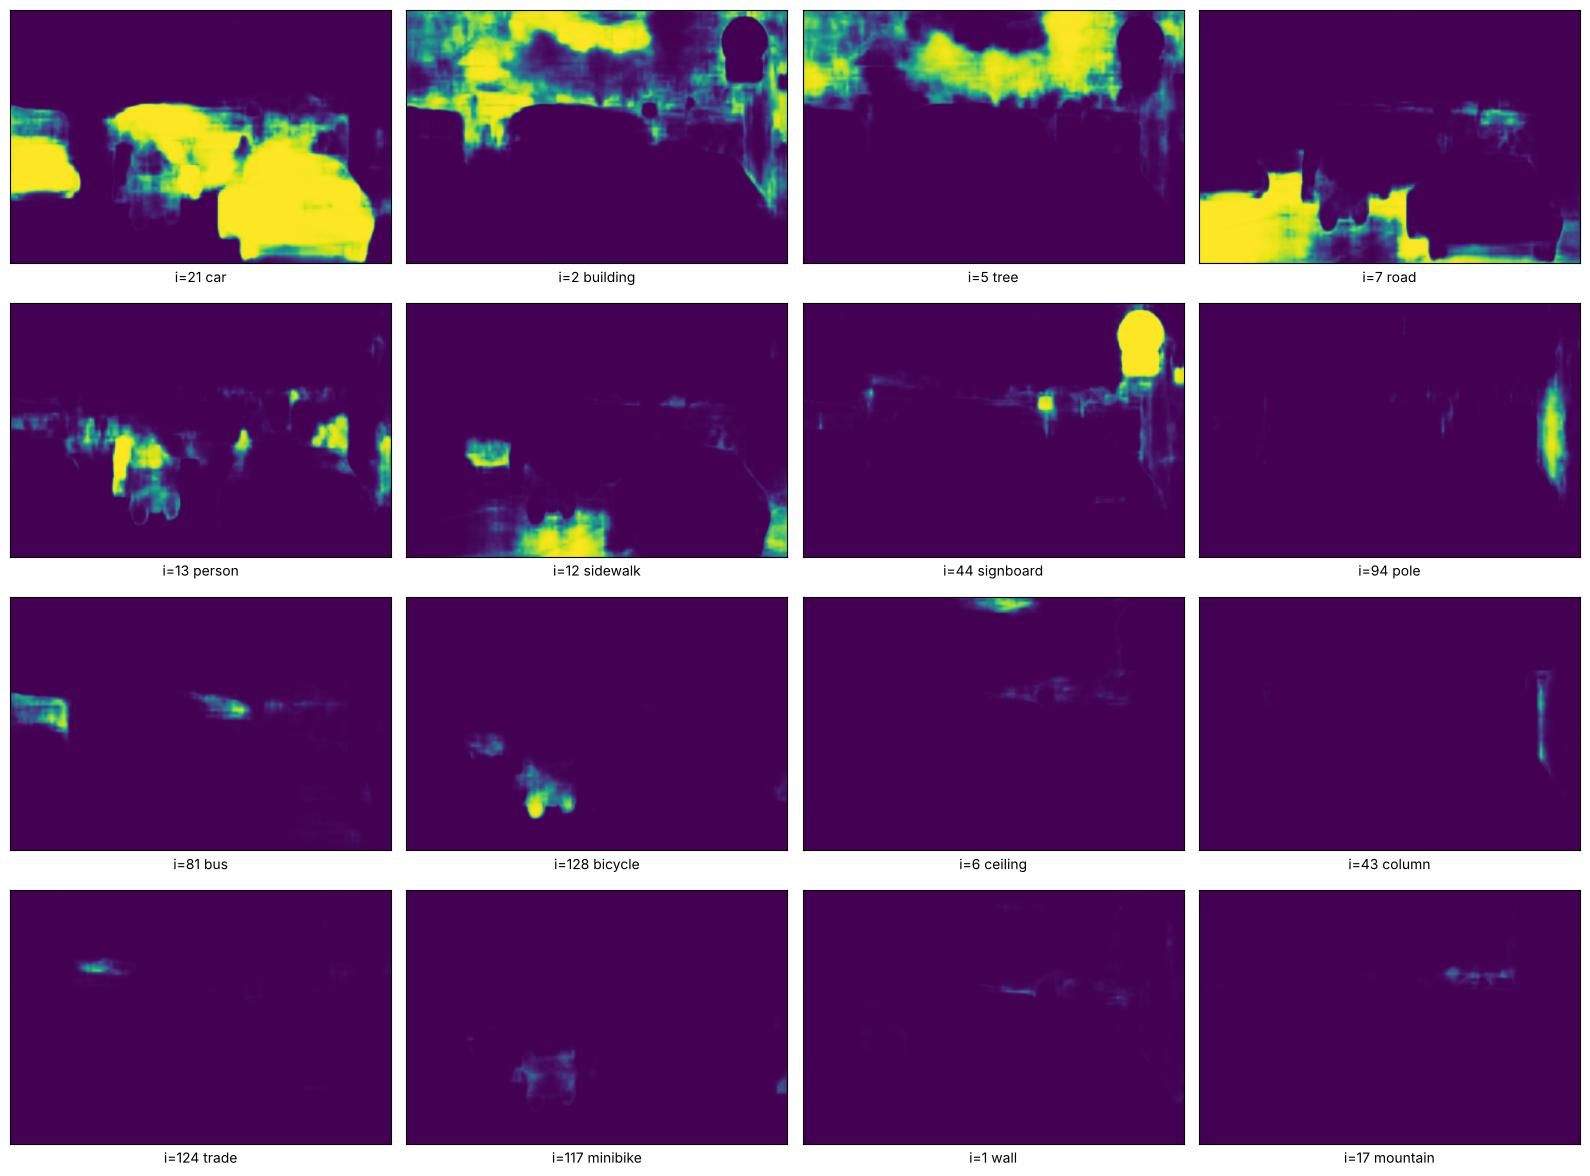

In [15]:
biggest_classes = area['id'].head(16).tolist()

plt.figure(figsize=(16, 12))
for i, class_id in enumerate(biggest_classes):
    plt.subplot(4, 4, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(predictions[:, :, class_id], vmin=0, vmax=1)
    plt.xlabel(f'i={class_id} {classes_segmentation[class_id]}')
plt.tight_layout()
plt.show()

Uždedame 4 didžiausias klases ant nuotraukos (originale klasės buvo parinktos ranka: `[2, 5, 13, 18]`).

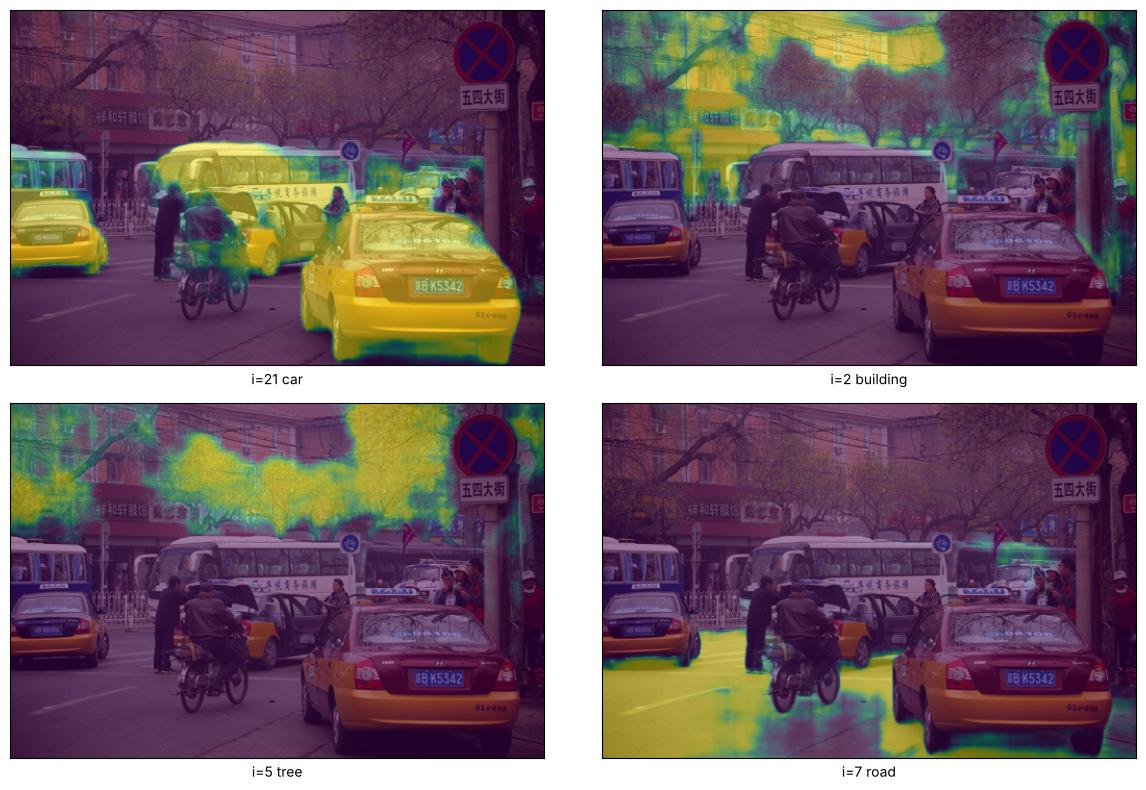

In [16]:
masks = [predictions[:, :, i] for i in biggest_classes[:4]]

plt.figure(figsize=(12, 8))
for i in range(len(masks)):
    plt.subplot(2, 2, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(seg_image)
    plt.imshow(masks[i], alpha=0.5, vmin=0, vmax=1)
    plt.xlabel(f'i={biggest_classes[i]} {classes_segmentation[biggest_classes[i]]}')
plt.tight_layout()
plt.show()

Galiausiai visas segmentavimo rezultatas vienoje spalvotoje nuotraukoje: kiekviena klasė savo spalva
(`SemanticPredictions` išėjimas). Legendoje yra klasės, užimančios bent 1 % ploto.

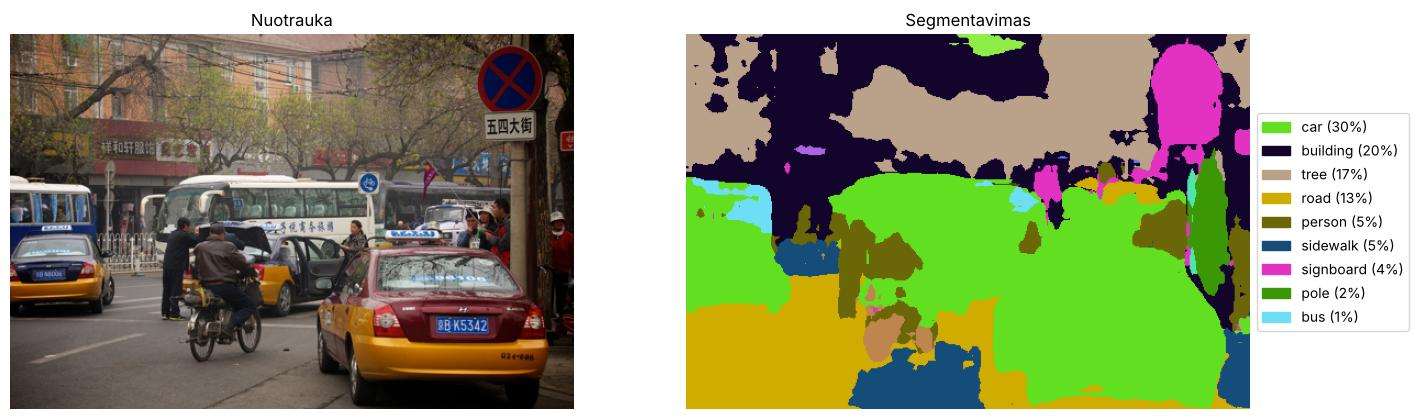

In [17]:
colors = np.random.default_rng(0).integers(0, 255, size=(len(classes_segmentation), 3)).astype('uint8')
colored = colors[seg_labels]

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1); plt.imshow(seg_image); plt.axis('off'); plt.title('Nuotrauka')
plt.subplot(1, 2, 2); plt.imshow(colored); plt.axis('off'); plt.title('Segmentavimas')
big = area[area['ploto dalis'] >= 0.01]
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[i] / 255) for i in big['id']]
plt.legend(handles, [f"{n} ({p:.0%})" for n, p in zip(big['klasė'], big['ploto dalis'])],
           loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.show()

---
# Išvados

| Užduotis | Modelis | Atsakymas | Gatvės nuotraukos pavyzdys |
|---|---|---|---|
| Klasifikavimas | EfficientNetV2-S, MobileNetV3-Large | viena klasė visai nuotraukai | `cab` (76 % / 80 %) |
| Iškarpos klasifikavimas | tie patys | viena klasė iškarpai | `moped` (77 % / 34 %) |
| Objektų aptikimas | SSD MobileNet V2 (Open Images V4) | klasė + stačiakampis kiekvienam objektui | 2 automobiliai, taksi, dviratis, žmogus, ratas |
| Segmentavimas | DeepLabV3 MobileNetV2 (ADE20K) | klasė kiekvienam taškui | automobilis 30 %, pastatas 20 %, medis 17 %, kelias 13 %, žmogus 5 % |

1. Trys užduotys duoda vis daugiau informacijos: klasifikavimas atsako **kas** yra nuotraukoje, aptikimas **kas ir kur**
   (stačiakampiai), segmentavimas **kuris taškas kam priklauso**.
2. Visi modeliai išmokyti su kitomis nuotraukomis ir kitam tikslui, bet su mūsų verslo nuotraukomis veikia be jokio papildomo mokymo.
3. Klaidų taip pat yra, ir jos pamokančios: mažas klasifikatorius biurą palaikė siuvimo mašina; detektorius nerado
   autobusų ir vaisių; segmentavimo modelis didelę autobuso dalį pažymėjo kaip automobilį (`bus` tik 1 %).
   Greiti „mobilūs“ modeliai yra mažiau tikslūs už didelius.
4. Kitą nuotrauką galima pasirinkti viršuje esančiame sąraše (`image_name`). Tada reikia iš naujo paleisti
   2 ir 3 skyrių langelius.